In [ ]:
# Cell 1: Import Libraries & Load Data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, StackingClassifier
from xgboost import XGBClassifier
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.metrics import accuracy_score, roc_curve, auc
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Load and explore the data
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('alzheimers_disease_data.csv')
print("Original shape:", df.shape)

Saving alzheimers_disease_data.csv to alzheimers_disease_data.csv
Original shape: (2149, 35)


In [ ]:
# Cell 2: Data Preprocessing & EDA (FIXED)
# Label Encoding
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))

# Handle missing values
print("Missing values:", df.isnull().sum().sum())
if df.isnull().sum().sum() > 0:
    df = df.fillna(df.mean())

# EDA
print("\nTarget distribution:")
target_col = 'Diagnosis' if 'Diagnosis' in df.columns else df.columns[-1]
print(df[target_col].value_counts())

# Outlier detection - use less aggressive approach
print(f"Original shape: {df.shape}")
z_scores = np.abs(stats.zscore(df.select_dtypes(include=[np.number])))
# Remove only rows with multiple outliers (more than 5 columns with outliers)
outlier_rows = (z_scores > 3).sum(axis=1)
df_clean = df[outlier_rows <= 5]

# If too many rows removed, use original data
if len(df_clean) < len(df) * 0.5:  # If less than 50% remains
    print("Too many outliers detected, using original data")
    df_clean = df.copy()

print(f"Shape after processing: {df_clean.shape}")

# Prepare data
X = df_clean.drop(columns=[target_col])
y = df_clean[target_col]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Missing values: 0

Target distribution:
Diagnosis
0    1389
1     760
Name: count, dtype: int64
Original shape: (2149, 35)
Shape after processing: (2149, 35)
Train: (1719, 34), Test: (430, 34)


In [ ]:
# Cell 3: Phase 1 - Base Models & Ensembles
models = {
    'LR': LogisticRegression(max_iter=1000, random_state=42),
    'SVM': SVC(probability=True, random_state=42),
    'RF': RandomForestClassifier(random_state=42),
    'XGB': XGBClassifier(random_state=42)
}

print("PHASE 1: BASE MODELS & ENSEMBLES")
print("="*50)

# Scale data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Individual models
base_results = {}
for name, model in models.items():
    if name in ['LR', 'SVM']:
        X_tr, X_te = X_train_scaled, X_test_scaled
    else:
        X_tr, X_te = X_train, X_test

    cv_scores = cross_val_score(model, x, y, cv=5, scoring='accuracy')
    model.fit(X_tr, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_te))
    base_results[name] = {'model': model, 'cv': cv_scores.mean(), 'test': test_acc}
    print(f"{name}: CV={cv_scores.mean():.4f}, Test={test_acc:.4f}")

# Ensembles
estimators = [(name, models[name]) for name in models.keys()]
hard_voting = VotingClassifier(estimators=estimators, voting='hard')
soft_voting = VotingClassifier(estimators=estimators, voting='soft')

for ensemble, name in [(hard_voting, 'Hard Voting'), (soft_voting, 'Soft Voting')]:
    cv_scores = cross_val_score(ensemble, x, y, cv=5, scoring='accuracy')
    ensemble.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, ensemble.predict(X_test))
    print(f"{name}: CV={cv_scores.mean():.4f}, Test={test_acc:.4f}")

PHASE 1: BASE MODELS & ENSEMBLES
LR: CV=0.8383, Test=0.8163
SVM: CV=0.8418, Test=0.8279
RF: CV=0.9331, Test=0.9488
XGB: CV=0.9482, Test=0.9674
Hard Voting: CV=0.8679, Test=0.8744
Soft Voting: CV=0.9401, Test=0.9442


In [ ]:
# Cell 4: Phase 2 - Feature Selection & Ensembles
print("\nPHASE 2: FEATURE SELECTION & ENSEMBLES")
print("="*50)

# SelectKBest (k=15)
selector_kbest = SelectKBest(score_func=f_classif, k=15)
X_train_kbest = selector_kbest.fit_transform(X_train_scaled, y_train)
X_test_kbest = selector_kbest.transform(X_test_scaled)
selected_features_kbest = X.columns[selector_kbest.get_support()]

# RFE (15 features)
rfe_selector = RFE(estimator=LogisticRegression(max_iter=1000), n_features_to_select=15)
X_train_rfe = rfe_selector.fit_transform(X_train_scaled, y_train)
X_test_rfe = rfe_selector.transform(X_test_scaled)
selected_features_rfe = X.columns[rfe_selector.get_support()]

print(f"KBest selected {len(selected_features_kbest)} features")
print(f"RFE selected {len(selected_features_rfe)} features")

# Evaluate models with feature selection
feature_sets = {
    'KBest': (X_train_kbest, X_test_kbest),
    'RFE': (X_train_rfe, X_test_rfe)
}

for fs_name, (X_tr_fs, X_te_fs) in feature_sets.items():
    print(f"\n{fs_name} Feature Selection:")

    # Individual models
    for name, model in models.items():
        cv_scores = cross_val_score(model, x, y, cv=5, scoring='accuracy')
        model.fit(X_tr_fs, y_train)
        test_acc = accuracy_score(y_test, model.predict(X_te_fs))
        print(f"  {name}: CV={cv_scores.mean():.4f}, Test={test_acc:.4f}")

    # Ensembles
    hard_voting_fs = VotingClassifier(estimators=estimators, voting='hard')
    soft_voting_fs = VotingClassifier(estimators=estimators, voting='soft')
    stacking_fs = StackingClassifier(estimators=estimators,
                                  final_estimator=LogisticRegression())

    for ensemble, e_name in [(hard_voting_fs, 'Hard Voting'),
                           (soft_voting_fs, 'Soft Voting'),
                           (stacking_fs, 'Stacking')]:
        cv_scores = cross_val_score(ensemble, x, y, cv=5, scoring='accuracy')
        ensemble.fit(X_tr_fs, y_train)
        test_acc = accuracy_score(y_test, ensemble.predict(X_te_fs))
        print(f"  {e_name}: CV={cv_scores.mean():.4f}, Test={test_acc:.4f}")


PHASE 2: FEATURE SELECTION & ENSEMBLES
KBest selected 15 features
RFE selected 15 features

KBest Feature Selection:
  LR: CV=0.8429, Test=0.8163
  SVM: CV=0.8581, Test=0.8698
  RF: CV=0.9424, Test=0.9558
  XGB: CV=0.9477, Test=0.9581
  Hard Voting: CV=0.9046, Test=0.9140
  Soft Voting: CV=0.9407, Test=0.9395
  Stacking: CV=0.9471, Test=0.9605

RFE Feature Selection:
  LR: CV=0.8412, Test=0.8163
  SVM: CV=0.8557, Test=0.8488
  RF: CV=0.9459, Test=0.9488
  XGB: CV=0.9471, Test=0.9651
  Hard Voting: CV=0.9081, Test=0.9116
  Soft Voting: CV=0.9383, Test=0.9372
  Stacking: CV=0.9517, Test=0.9558


In [ ]:
# Cell 5: Phase 3 - Hyperparameter Tuning & Final Evaluation
print("\nPHASE 3: HYPERPARAMETER TUNING & FINAL EVALUATION")
print("="*50)

# Use KBest features for tuning
X_train_final = X_train_kbest
X_test_final = X_test_kbest

# Parameter grids
param_grids = {
    'LR': {'C': [0.1, 1, 10], 'penalty': ['l2']},
    'SVM': {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
    'RF': {'n_estimators': [100, 200], 'max_depth': [10, 20]},
    'XGB': {'n_estimators': [100, 200], 'max_depth': [3, 6], 'learning_rate': [0.1, 0.2]}
}

# Tune models
best_models = {}
for name, model in models.items():
    grid_search = GridSearchCV(model, param_grids[name], cv=3, scoring='accuracy', n_jobs=-1)
    grid_search.fit(X_train_final, y_train)
    best_models[name] = grid_search.best_estimator_
    print(f"{name} tuned - Best params: {grid_search.best_params_}, Score: {grid_search.best_score_:.4f}")

# Final ensembles with tuned models
tuned_estimators = [(name, model) for name, model in best_models.items()]

hard_voting_tuned = VotingClassifier(estimators=tuned_estimators, voting='hard')
soft_voting_tuned = VotingClassifier(estimators=tuned_estimators, voting='soft')
stacking_tuned = StackingClassifier(estimators=tuned_estimators,
                                 final_estimator=LogisticRegression())

# Evaluate tuned ensembles
final_results = {}
for ensemble, e_name in [(hard_voting_tuned, 'Hard Voting Tuned'),
                       (soft_voting_tuned, 'Soft Voting Tuned'),
                       (stacking_tuned, 'Stacking Tuned')]:
    cv_scores = cross_val_score(ensemble, X_train_final, y_train, cv=5, scoring='accuracy')
    ensemble.fit(X_train_final, y_train)
    test_acc = accuracy_score(y_test, ensemble.predict(X_test_final))
    final_results[e_name] = {'cv': cv_scores.mean(), 'test': test_acc}
    print(f"{e_name}: CV={cv_scores.mean():.4f}, Test={test_acc:.4f}")


PHASE 3: HYPERPARAMETER TUNING & FINAL EVALUATION
LR tuned - Best params: {'C': 1, 'penalty': 'l2'}, Score: 0.8447
SVM tuned - Best params: {'C': 1, 'kernel': 'rbf'}, Score: 0.8557
RF tuned - Best params: {'max_depth': 10, 'n_estimators': 200}, Score: 0.9418
XGB tuned - Best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}, Score: 0.9506
Hard Voting Tuned: CV=0.9040, Test=0.9116
Soft Voting Tuned: CV=0.9366, Test=0.9372
Stacking Tuned: CV=0.9511, Test=0.9558



FINAL ROC ANALYSIS & SUMMARY


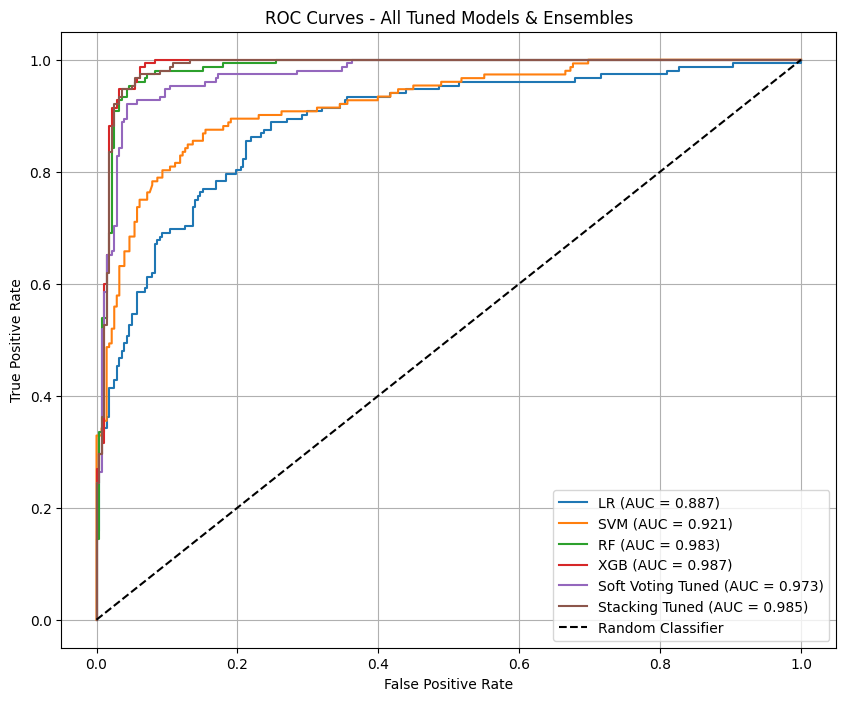


BEST PERFORMING MODELS:
Best Ensemble: Stacking Tuned with Test Accuracy: 0.9558
Best Individual: XGB with Test Accuracy: 0.9581


In [ ]:
# Cell 6: ROC Curves & Summary
print("\nFINAL ROC ANALYSIS & SUMMARY")
print("="*50)

# Combine all models for ROC
all_models = {}
all_models.update(best_models)
all_models['Hard Voting Tuned'] = hard_voting_tuned
all_models['Soft Voting Tuned'] = soft_voting_tuned
all_models['Stacking Tuned'] = stacking_tuned

# Plot ROC curves
plt.figure(figsize=(10, 8))
for name, model in all_models.items():
    if hasattr(model, 'predict_proba'):
        model.fit(X_train_final, y_train)
        y_proba = model.predict_proba(X_test_final)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All Tuned Models & Ensembles')
plt.legend()
plt.grid(True)
plt.show()

# Final summary
print("\nBEST PERFORMING MODELS:")
best_model = max(final_results.items(), key=lambda x: x[1]['test'])
print(f"Best Ensemble: {best_model[0]} with Test Accuracy: {best_model[1]['test']:.4f}")

best_individual = max(best_models.keys(),
                    key=lambda x: accuracy_score(y_test, best_models[x].predict(X_test_final)))
best_ind_acc = accuracy_score(y_test, best_models[best_individual].predict(X_test_final))
print(f"Best Individual: {best_individual} with Test Accuracy: {best_ind_acc:.4f}")